24BAD010-Anusri T
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


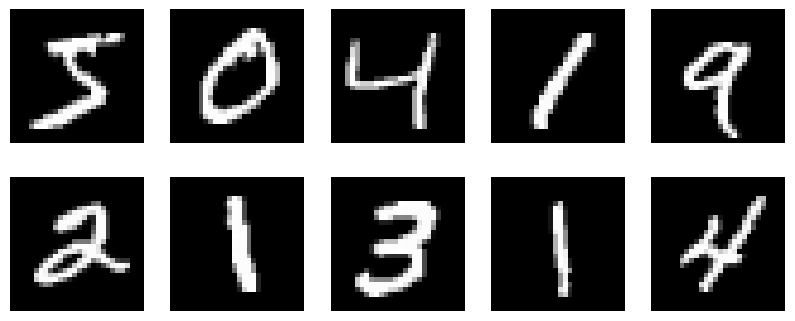

Image dimensions: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255
Number of training images: 60000
Reshaped data: (60000, 28, 28, 1)
Normalized range: -1.0 to 1.0
Dataset prepared successfully!


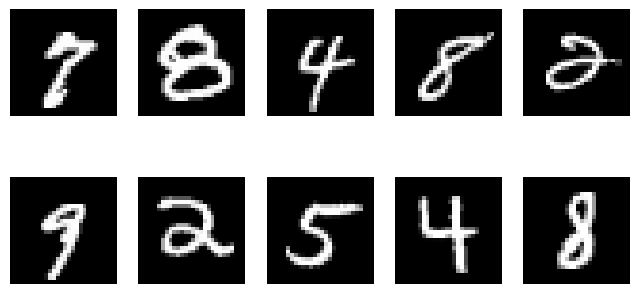

In [ ]:
print("24BAD010-Anusri T")
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.axis('off')
plt.show()

print("Image dimensions:", x_train[0].shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Number of training images:", len(x_train))

x_train = (x_train.astype('float32') - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)

print("Reshaped data:", x_train.shape)
print("Normalized range:", x_train.min(), "to", x_train.max())

BUFFER_SIZE = 60000
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

print("Dataset prepared successfully!")

plt.figure(figsize=(8, 4))
for images in train_dataset.take(1):
    for i in range(10):
        plt.subplot(2, 5, i+1)
        plt.imshow(images[i, :, :, 0], cmap='gray')
        plt.axis('off')
plt.show()

In [ ]:
print("24BAD010-Anusri T")
import tensorflow as tf
from tensorflow.keras import layers, Sequential

latent_dim = 100

generator = Sequential([
    layers.Dense(7 * 7 * 256, input_shape=(latent_dim,)),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 256)),
    layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', activation='tanh')
])

discriminator = Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same'),
    layers.LeakyReLU(),
    layers.Dropout(0.3),
    layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
    layers.LeakyReLU(),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1, activation='sigmoid')
])

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

cross_entropy = tf.keras.losses.BinaryCrossentropy()

generator_loss = lambda fake_output: cross_entropy(tf.ones_like(fake_output), fake_output)
discriminator_loss = lambda real_output, fake_output: (
    cross_entropy(tf.ones_like(real_output), real_output) +
    cross_entropy(tf.zeros_like(fake_output), fake_output)
)

generator.summary()
discriminator.summary()

gan = Sequential([generator, discriminator])

print("GAN Model Summary:")
gan.summary()

24BAD010-Anusri T


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,266,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,328 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,343,681 (8.94 MB)

 Trainable params: 2,318,209 (8.84 MB)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 28, 28, 1)      │     2,343,681 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 1)              │       212,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,556,546 (9.75 MB)

 Trainable params: 2,531,074 (9.66 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [ ]:
print("24BAD010-Anusri T")
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Sequential

(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

x_train = (x_train.astype('float32') - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(60000).batch(128)

noise_dim = 100

generator = Sequential([
    layers.Input(shape=(noise_dim,)),
    layers.Dense(7 * 7 * 256),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 256)),
    layers.Conv2DTranspose(128, 5, strides=1, padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(64, 5, strides=2, padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(1, 5, strides=2, padding='same', activation='tanh')
])

discriminator = Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 5, strides=2, padding='same'),
    layers.LeakyReLU(),
    layers.Dropout(0.3),
    layers.Conv2D(128, 5, strides=2, padding='same'),
    layers.LeakyReLU(),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1, activation='sigmoid')
])

generator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)

cross_entropy = tf.keras.losses.BinaryCrossentropy()

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

@tf.function
def train_step(images):
    noise = tf.random.normal([tf.shape(images)[0], noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

    return gen_loss, disc_loss

EPOCHS = 50
gen_losses = []
disc_losses = []

seed = tf.random.normal([16, noise_dim])

for epoch in range(EPOCHS):
    total_gen_loss = 0.0
    total_disc_loss = 0.0
    batches = 0

    for image_batch in train_dataset:
        gen_loss, disc_loss = train_step(image_batch)
        total_gen_loss += float(gen_loss)
        total_disc_loss += float(disc_loss)
        batches += 1

    avg_gen_loss = total_gen_loss / batches
    avg_disc_loss = total_disc_loss / batches

    gen_losses.append(avg_gen_loss)
    disc_losses.append(avg_disc_loss)

    print("Epoch:", epoch + 1,
          "Generator Loss:", round(avg_gen_loss, 4),
          "Discriminator Loss:", round(avg_disc_loss, 4))

    if (epoch + 1) % 10 == 0:
        predictions = generator(seed, training=False)

        plt.figure(figsize=(6, 6))
        for i in range(16):
            plt.subplot(4, 4, i + 1)
            plt.imshow(predictions[i, :, :, 0], cmap='gray')
            plt.axis('off')

        plt.suptitle("Generated Images - Epoch " + str(epoch + 1))
        plt.show()

plt.figure(figsize=(10, 5))
plt.plot(gen_losses, label='Generator Loss')
plt.plot(disc_losses, label='Discriminator Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('GAN Training Performance')
plt.legend()
plt.grid()
plt.show()

print("GAN Training Completed Successfully!")


24BAD010-Anusri T
Epoch: 1 Generator Loss: 0.708 Discriminator Loss: 1.3132
Epoch: 2 Generator Loss: 0.7618 Discriminator Loss: 1.3245
Epoch: 3 Generator Loss: 0.8259 Discriminator Loss: 1.2678
Epoch: 4 Generator Loss: 0.8532 Discriminator Loss: 1.2609
Epoch: 5 Generator Loss: 0.7912 Discriminator Loss: 1.3097


24BAD010-Anusri T
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step
Feature shape: (1000, 6272)


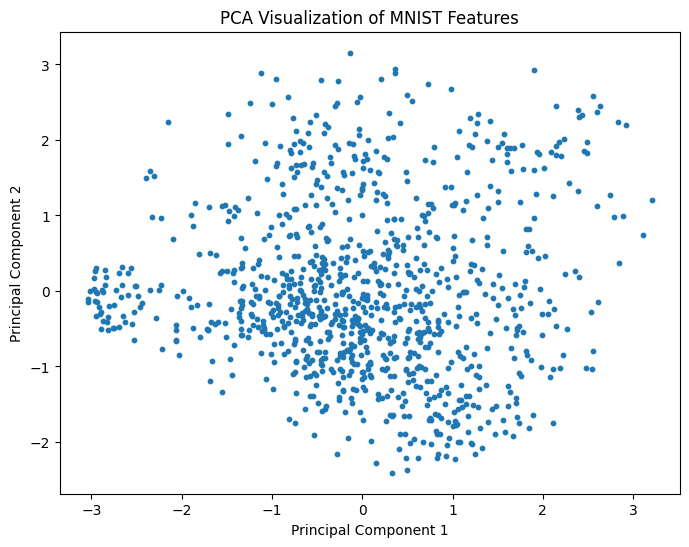

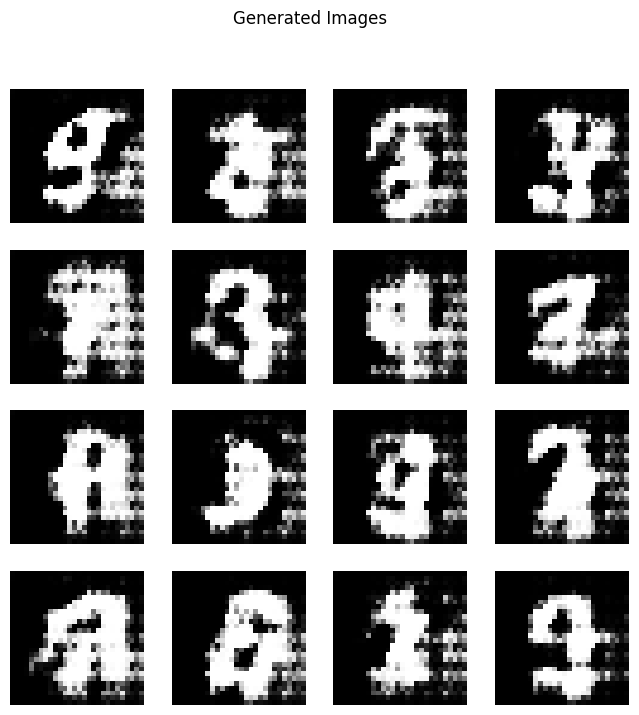

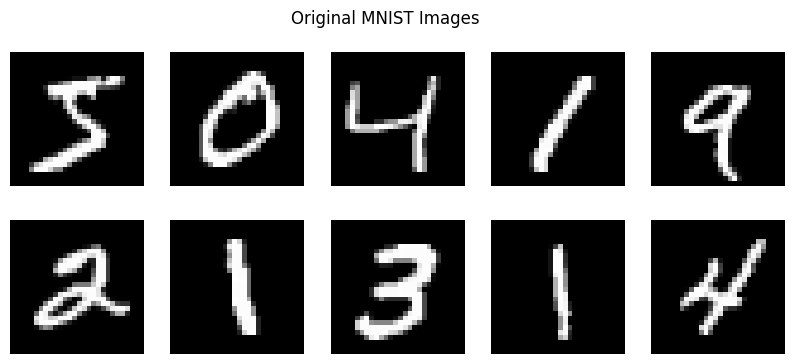

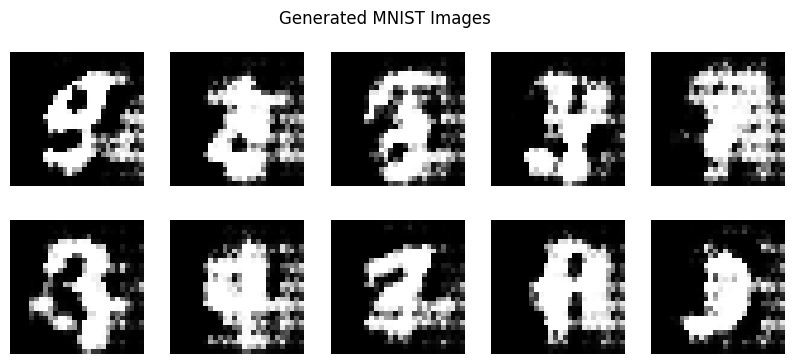

Original image shape: (60000, 28, 28, 1)
Generated image shape: (16, 28, 28, 1)
Explained variance ratio: [0.09048578 0.07732292]
Feature extraction completed successfully!
Synthetic image generation completed successfully!
Part D Completed Successfully!


In [ ]:
print("24BAD010-Anusri T")
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

(x_test, _), (_, _) = tf.keras.datasets.mnist.load_data()

x_test = (x_test.astype('float32') - 127.5) / 127.5
x_test = x_test.reshape(-1, 28, 28, 1)

discriminator(tf.zeros((1, 28, 28, 1)))

feature_extractor = tf.keras.Model(
    inputs=discriminator.inputs,
    outputs=discriminator.layers[-2].output
)

features = feature_extractor.predict(x_test[:1000])

print("Feature shape:", features.shape)

pca = PCA(n_components=2)
reduced_features = pca.fit_transform(features)

plt.figure(figsize=(8, 6))
plt.scatter(reduced_features[:, 0], reduced_features[:, 1], s=10)
plt.title("PCA Visualization of MNIST Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

noise = tf.random.normal([16, 100])
generated_images = generator(noise, training=False)

plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i, :, :, 0], cmap='gray')
    plt.axis('off')
plt.suptitle("Generated Images")
plt.show()

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i, :, :, 0], cmap='gray')
    plt.axis('off')
plt.suptitle("Original MNIST Images")
plt.show()

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_images[i, :, :, 0], cmap='gray')
    plt.axis('off')
plt.suptitle("Generated MNIST Images")
plt.show()

print("Original image shape:", x_test.shape)
print("Generated image shape:", generated_images.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Feature extraction completed successfully!")
print("Synthetic image generation completed successfully!")
print("Part D Completed Successfully!")
